# Practice 1 - LangGraph Essentials

LangGraph로 Agent를 공부하면 복잡한 AI 워크플로우를 그래프 기반으로 구조화해 제어하기 쉽습니다.<br> LangChain의 확장으로, 다중 에이전트 시스템과 상태 관리를 효과적으로 구현할 수 있어 실무에서 필수적입니다.

본 실습을 통해 앞으로 자주 사용하게 될 Agent FrameWork 중 하나인 LangGraph에 대해 이해해봅니다.

---
## LangGraph Essentials

에이전트 디자인 패턴을 구현하기 전에, LangGraph의 핵심 개념을 이해해야 합니다.

### LangGraph란?

LangGraph는 **그래프 기반의 워크플로우 프레임워크**로, LLM 애플리케이션을 구조화된 방식으로 구축할 수 있게 해줍니다.

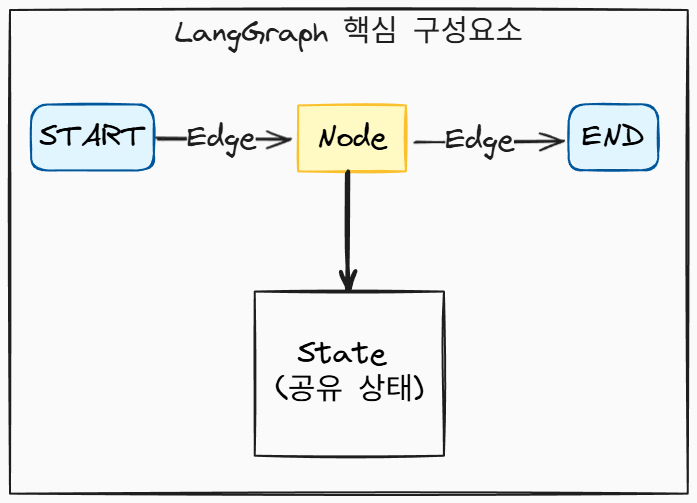

#### 핵심 개념 4가지

| 개념 | 설명 | 역할 |
|------|------|------|
| **State** | 그래프 전체에서 공유되는 데이터 | 노드 간 정보 전달 |
| **Node** | 실제 작업을 수행하는 함수 | LLM 호출, 데이터 처리 |
| **Edge** | 노드 간 연결 (실행 흐름) | 순서 결정, 분기 처리 |
| **Memory** | 호출 간 상태 유지 | 대화 히스토리 저장 |

### 1. State (상태) 정의

State는 **TypedDict**를 사용하여 그래프 전체에서 공유되는 데이터 구조를 정의합니다.

### 💡 핵심 요약: SimpleState와 TypedDict 완벽 복습하기

이 과정에서 헷갈렸던 핵심 개념을 한눈에 볼 수 있도록 요약한 문서입니다.

#### 1. `TypedDict` 클래스는 설계도(Type Hint)일 뿐입니다
* `class SimpleState(TypedDict):` 코드는 실제 데이터를 담고 있는 상자가 아니라, **"앞으로 만들 딕셔너리는 이 규격을 지켜야 해"**라고 선언하는 **가이드라인(설계도)**입니다.
* 그렇기 때문에 클래스를 선언하는 것만으로는 실제 데이터 객체가 메모리에 만들어지지 않으며, 단지 정적 타입 분석기나 개발자에게 정보(룰)를 제공할 뿐입니다.

#### 2. 실제 데이터를 생성할 때는 일반 딕셔너리(`dict`) 문법을 사용합니다
* `TypedDict`를 상속받은 클래스는 일반 클래스처럼 `SimpleState()` 형태로 인스턴스를 생성하지 않습니다.
* 대신 우리가 잘 알고 있는 **일반 딕셔너리 형태(`{ "key": value }`)**로 데이터를 만들고, 변수 옆에 `: SimpleState`라고 붙여주어 설계도를 준수하고 있음을 선언합니다.

```python
# 1. 설계도 정의
class SimpleState(TypedDict):
    message: str

# 2. 실제 데이터 생성 (인스턴스화가 아닌 일반 dict 생성)
my_state: SimpleState = {
    "message": "안녕하세요!"
}
```

#### 3. 콜론(`:`)의 쓰임새 구별하기
* **타입 선언 `:` (Type Hint)**: 변수나 클래스 속성 뒤에 붙여 타입을 명시할 때 씁니다.
  * `message: str` (message 키의 값은 문자열이어야 해)
  * `my_state: SimpleState` (my_state 변수는 SimpleState 규격이어야 해)
* **값 매핑 `:` (Key-Value)**: 딕셔너리 내부에서 실제 Key와 Value를 짝지어 줄 때 씁니다.
  * `"message": "안녕하세요!"`

In [ ]:
from typing import TypedDict, Annotated, List
from langgraph.graph import StateGraph, START, END
import operator

# 기본 state 정의
class SimpleState(TypedDict):
  message: str  # 단일 값

# Reducer를 사용한 State 정의 (값 누적)
class AccumulatorState(TypedDict):
  messages: Annotated[List[str], operator.add]  # 리스트에 값추가

print("State 정의 완료")
print("- SimpleState: 단일 메세지 저장")
print("- AccumulatorState: 메세지 리스트 누적(Reducer 사용)")

State 정의 완료
- SimpleState: 단일 메세지 저장
- AccumulatorState: 메세지 리스트 누적(Reducer 사용)


In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 기본 State 정의
class SimpleState(TypedDict):
    message: str  # 단일 값

print("- SimpleState: 단일 메시지 저장")

- SimpleState: 단일 메시지 저장


In [ ]:
# 1. SimpleState 규격에 맞게 데이터를 생성합니다. (딕셔너리 형태)
my_state: SimpleState = {
    "message": "안녕하세요! LangGraph 공부 중입니다."
}

# 2. 내부에 담긴 메세지를 호출(가져오기)하는 2가지 방법

# 방법 [1]: 대괄호([]) 사용하기 (가장 기본)
print("방법 1로 가져온 메시지:", my_state["message"])

# 방법 [2]: .get() 메서드 사용하기 (데이터가 없을 때 에러 방지용으로 안전)
print("방법 2로 가져온 메시지:", my_state.get("message"))

방법 1로 가져온 메시지: 안녕하세요! LangGraph 공부 중입니다.
방법 2로 가져온 메시지: 안녕하세요! LangGraph 공부 중입니다.


#### Reducer란?

`Annotated[List[str], operator.add]`에서 `operator.add`가 **Reducer** 역할을 합니다.

```python
# Reducer 없이 (덮어쓰기)
state["messages"] = ["새 메시지"]  # 기존 값 사라짐

# Reducer 사용 (누적)
state["messages"] = ["새 메시지"]  # 기존 값 + 새 메시지
# 결과: ["기존1", "기존2", "새 메시지"]
```

In [ ]:
import operator
from typing import TypedDict, Annotated, List

# Reducer를 사용한 State 정의 (값 누적)
class AccumulatorState(TypedDict):
    messages: Annotated[List[str], operator.add]  # 리스트에 값 추가

print("- AccumulatorState: 메시지 리스트 누적 (Reducer 사용)")

- AccumulatorState: 메시지 리스트 누적 (Reducer 사용)


### 2. Node (노드) 정의

Node는 **State를 입력받아 업데이트된 State를 반환**하는 Python 함수입니다.

In [ ]:
# 노드 함수 정의
def node_a(state: AccumulatorState) -> AccumulatorState:
    """노드 A: 상태에 'A' 추가"""
    print(f"  [Node A] 현재 상태: {state['messages']}")
    return {"messages": ["A 처리완료"]}

def node_b(state: AccumulatorState) -> AccumulatorState:
    """노드 B: 상태에 'B' 추가"""
    print(f"  [Node B] 현재 상태: {state['messages']}")
    return {"messages": ["B 처리완료"]}

def node_c(state: AccumulatorState) -> AccumulatorState:
    """노드 C: 상태에 'C' 추가"""
    print(f"  [Node C] 현재 상태: {state['messages']}")
    return {"messages": ["C 처리완료"]}

print("✅ 노드 함수 정의 완료")

✅ 노드 함수 정의 완료


### 3. Graph 구성 및 실행

StateGraph를 사용하여 노드를 연결하고 그래프를 실행합니다.

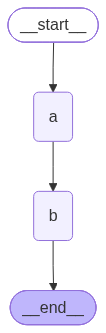

In [ ]:
import nest_asyncio
nest_asyncio.apply() # mermaid 랜더링을 위해 중첩 이벤트 루프 허용

from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod

# 1. 그래프 빌더 생성
builder = StateGraph(AccumulatorState)

# 2. 노드 추가
builder.add_node("a", node_a)
builder.add_node("b", node_b)

# 3. 엣지 추가 (실행 순서 정의)
builder.add_edge(START, "a")  # 시작 → A
builder.add_edge("a", "b")     # A → B
builder.add_edge("b", END)     # B → 종료

# 4. 그래프 컴파일
graph = builder.compile()

# 5. 그래프 시각화
display(Image(graph.get_graph().draw_mermaid_png()))
# print("\n✅ 순차 실행 그래프 (START → A → B → END)")

In [ ]:
# 그래프 실행
initial_state = {"messages": ["시작"]}
print("🚀 그래프 실행 시작\n")

result = graph.invoke(initial_state)

print(f"\n📊 최종 결과: {result['messages']}")

🚀 그래프 실행 시작

  [Node A] 현재 상태: ['시작']
  [Node B] 현재 상태: ['시작', 'A 처리완료']

📊 최종 결과: ['시작', 'A 처리완료', 'B 처리완료']


### 4. 병렬 실행 (Parallel Execution)

한 노드에서 **여러 개의 outgoing edge**가 있으면 병렬로 실행됩니다.

노드 A에서 B와 C로 동시에 분기하고, D에서 다시 합쳐집니다.

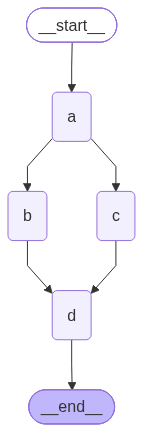


✅ 병렬 실행 그래프 (A에서 B,C로 분기 → D에서 합류)


In [ ]:
# 병렬 실행 그래프 구성
def node_d(state: AccumulatorState) -> AccumulatorState:
    """노드 D: 병합 노드"""
    print(f"  [Node D] 현재 상태: {state['messages']}")
    return {"messages": ["D 병합완료"]}

# 새 그래프 빌더
parallel_builder = StateGraph(AccumulatorState)

# 노드 추가
parallel_builder.add_node("a", node_a)
parallel_builder.add_node("b", node_b)
parallel_builder.add_node("c", node_c)
parallel_builder.add_node("d", node_d)

# 엣지 추가 (병렬 분기)
parallel_builder.add_edge(START, "a")
parallel_builder.add_edge("a", "b")  # A → B (분기 1)
parallel_builder.add_edge("a", "c")  # A → C (분기 2)
parallel_builder.add_edge("b", "d")  # B → D (합류)
parallel_builder.add_edge("c", "d")  # C → D (합류)
parallel_builder.add_edge("d", END)

# 컴파일 및 시각화
parallel_graph = parallel_builder.compile()
display(Image(parallel_graph.get_graph().draw_mermaid_png()))
# print(graph.get_graph().draw_mermaid())
print("\n✅ 병렬 실행 그래프 (A에서 B,C로 분기 → D에서 합류)")

In [ ]:
# 병렬 그래프 실행
print("🚀 병렬 그래프 실행 시작\n")
parallel_result = parallel_graph.invoke({"messages": ["시작"]})

print(f"\n📊 최종 결과: {parallel_result['messages']}")
print("\n💡 B와 C가 동시에 실행되고, Reducer가 결과를 병합합니다!")

🚀 병렬 그래프 실행 시작

  [Node A] 현재 상태: ['시작']
  [Node B] 현재 상태: ['시작', 'A 처리완료']
  [Node C] 현재 상태: ['시작', 'A 처리완료']
  [Node D] 현재 상태: ['시작', 'A 처리완료', 'B 처리완료', 'C 처리완료']

📊 최종 결과: ['시작', 'A 처리완료', 'B 처리완료', 'C 처리완료', 'D 병합완료']

💡 B와 C가 동시에 실행되고, Reducer가 결과를 병합합니다!


### 🧪 실험: 한쪽 노드의 실행 시간을 늘리면 병합 순서가 바뀔까?

`time` 라이브러리를 사용해 `node_b`에만 `time.sleep(1)`을 주어 강제로 지연을 발생시키고 실행 결과를 확인해 봅니다.

In [ ]:
import time
from langgraph.graph import StateGraph, START, END

# 1. 실행 시간이 다른 노드 재정의
def slow_node_b(state: AccumulatorState) -> AccumulatorState:
    print("  [Node B] 1초 대기 시작...")
    time.sleep(1)
    print("  [Node B] 대기 완료!")
    return {"messages": ["B 처리완료 (지연)"]}

def fast_node_c(state: AccumulatorState) -> AccumulatorState:
    print("  [Node C] 즉시 처리 중!")
    return {"messages": ["C 처리완료 (신속)"]}

# 2. 실험용 새 병렬 그래프 구성
exp_builder = StateGraph(AccumulatorState)
exp_builder.add_node("a", node_a)
exp_builder.add_node("b", slow_node_b) # 느린 노드
exp_builder.add_node("c", fast_node_c) # 빠른 노드
exp_builder.add_node("d", node_d)

exp_builder.add_edge(START, "a")
exp_builder.add_edge("a", "b")
exp_builder.add_edge("a", "c")
exp_builder.add_edge("b", "d")
exp_builder.add_edge("c", "d")
exp_builder.add_edge("d", END)

exp_graph = exp_builder.compile()
print("✅ 실험용 그래프 컴파일 완료. 아래 코드를 실행해 순서를 확인해 보세요!")

✅ 실험용 그래프 컴파일 완료. 아래 코드를 실행해 순서를 확인해 보세요!


In [ ]:
# 3. 실험 그래프 실행 및 결과 출력
print("🚀 실험 그래프 실행 시작\n")
exp_result = exp_graph.invoke({"messages": ["시작"]})

print(f"\n📊 최종 결과 메시지 순서: {exp_result['messages']}")

🚀 실험 그래프 실행 시작

  [Node A] 현재 상태: ['시작']
  [Node B] 1초 대기 시작...
  [Node C] 즉시 처리 중!
  [Node B] 대기 완료!
  [Node D] 현재 상태: ['시작', 'A 처리완료', 'B 처리완료 (지연)', 'C 처리완료 (신속)']

📊 최종 결과 메시지 순서: ['시작', 'A 처리완료', 'B 처리완료 (지연)', 'C 처리완료 (신속)', 'D 병합완료']


- 동작 방식

    `A 실행 → B, C 동시 실행 (parallel) → Reducer가 결과 병합 → D 실행`

### 🔄 병렬 실행 및 병합의 상세 흐름 (시간적 순서)

노드 A에서 분기하여 B와 C가 병렬로 실행되고 D에서 병합될 때, 내부적으로 상태(State)는 다음 순서로 엄격하게 관리됩니다.

```mermaid
graph TD
    A[1. 노드 A 완료<br>상태: 시작, A완료] -->|2. 스냅샷 복사| B[노드 B 실행<br>입력: 시작, A완료]
    A -->|2. 스냅샷 복사| C[노드 C 실행<br>입력: 시작, A완료]
    B -->|3. 독립 반환| R[4. Reducer 순차 병합]
    C -->|3. 독립 반환| R
    R -->|5. 최종 전달| D[노드 D 실행<br>입력: 시작, A완료, B완료, C완료]
```

#### 상세 단계별 흐름
1. **기준 상태 결정 (노드 A 완료)**
   * 노드 A가 종료되고 전체 그래프 상태는 **`['시작', 'A 처리완료']`**가 됩니다.

2. **스냅샷 복사 (독립성 보장)**
   * 노드 B와 노드 C는 동시에 실행될 때, 노드 A가 반환한 최종 상태(`['시작', 'A 처리완료']`)를 **각각 개별 공간으로 똑같이 복사(스냅샷)**해 가져갑니다.
   * *주의*: 이 단계에서 노드 B와 C는 상대방의 처리 내용을 알 수 없는 완전히 격리된 상태입니다.

3. **개별 결과 반환**
   * **노드 B**는 자신의 연산 결과인 `{"messages": ["B 처리완료"]}`를 반환합니다.
   * **노드 C**는 자신의 연산 결과인 `{"messages": ["C 처리완료"]}`를 반환합니다.

4. **Reducer 순차 병합 (Merge Stage)**
   * LangGraph 엔진은 수집된 결과 조각들을 모아서 등록된 Reducer(`operator.add`)를 통해 순서대로 합산합니다.
   * **기존 상태** (`['시작', 'A 처리완료']`)
   * ➔ **B 결과 합산** (`['시작', 'A 처리완료', 'B 처리완료']`)
   * ➔ **C 결과 합산** (`['시작', 'A 처리완료', 'B 처리완료', 'C 처리완료']`)

5. **최종 노드 D 실행**
   * 병합이 완료되어 완벽한 흐름이 복원된 최종 상태를 가지고 노드 D가 호출되어 최종 정리를 처리합니다.

### 5. 조건부 엣지 (Conditional Edges)

`add_conditional_edges()`를 사용하면 **상태에 따라 동적으로 경로를 결정**할 수 있습니다.

라우팅 함수가 상태를 보고 어느 노드로 갈지 결정합니다.

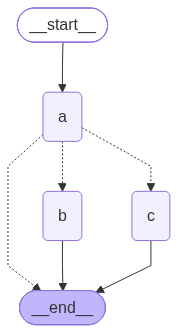

In [ ]:
from typing import Literal

# 라우팅에 사용할 State 정의
class RouterState(TypedDict):
    messages: Annotated[List[str], operator.add]
    route: str  # 라우팅 결정 값

# 라우팅 함수 정의
def routing_function(state: RouterState) -> Literal["b", "c", END]:
    """상태의 route 값에 따라 다음 노드 결정"""
    route = state.get("route", "b")
    print(f"  [Router] route={route} → {route} 노드로 이동")
    if route == "b":
        return "b"
    elif route == "c":
        return "c"
    else:
        return END

# 조건부 그래프 빌더
cond_builder = StateGraph(RouterState)
cond_builder.add_node("a", lambda s: {"messages": ["A"], "route": s["route"]})
cond_builder.add_node("b", lambda s: {"messages": ["B (route=b)"]})
cond_builder.add_node("c", lambda s: {"messages": ["C (route=c)"]})

# 엣지 설정
cond_builder.add_edge(START, "a")
cond_builder.add_conditional_edges("a", routing_function)  # 조건부 엣지!
cond_builder.add_edge("b", END)
cond_builder.add_edge("c", END)

cond_graph = cond_builder.compile()
display(Image(cond_graph.get_graph().draw_mermaid_png()))

```markdown
### 🔍 위 조건부 라우팅(Conditional Routing) 코드 완벽 해부

이 코드는 **"A 노드를 처리한 뒤, 우리가 설정한 값(`route`)에 따라 B 노드로 갈지, C 노드로 갈지 동적으로 결정하자!"**라는 시나리오를 구현한 것입니다.

---

#### 1. 상태(`State`) 정의
```python
class RouterState(TypedDict):
    messages: Annotated[List[str], operator.add] # 메시지 기록을 누적할 리스트
    route: str  # 어디로 갈지 가리키는 나침반 역할 ("b" 또는 "c")
```
* 그래프가 기억할 데이터 규격입니다.
* 특히 `route`라는 값이 들어있어, 이 상자의 내용물을 보고 길을 찾을 예정입니다.

---

#### 2. 라우터 함수 (`routing_function`) 정의
```python
def routing_function(state: RouterState) -> Literal["b", "c", END]:
    route = state.get("route", "b") # 현재 상태에서 'route' 값을 꺼냅니다. (없으면 기본값 "b")
    if route == "b":
        return "b"                  # "b" 문자열을 리턴하면 "b" 노드로 이동합니다.
    elif route == "c":
        return "c"                  # "c" 문자열을 리턴하면 "c" 노드로 이동합니다.
    else:
        return END                  # 그 외에는 그래프를 종료(END)합니다.
```
* 이 함수는 그래프의 **'이정표(신호등)'**입니다.
* 상태를 입력받아 그중 `route` 값을 읽고, **다음으로 갈 노드의 이름(문자열)**을 반환해 줍니다.

---

#### 3. 노드와 엣지 설정
```python
cond_builder = StateGraph(RouterState)

# 람다(lambda) 함수를 사용해 간단하게 노드를 정의했습니다.
cond_builder.add_node("a", lambda s: {"messages": ["A"], "route": s["route"]})
cond_builder.add_node("b", lambda s: {"messages": ["B (route=b)"]})
cond_builder.add_node("c", lambda s: {"messages": ["C (route=c)"]})
```
* `a` 노드는 실행되면 메시지에 `"A"`를 기록하고, 입력받은 `route` 값을 그대로 넘겨줍니다.
* `b` 노드와 `c` 노드는 각각 자신이 호출되었음을 기록합니다.

---

#### 4. 핵심: 조건부 엣지 연결
```python
cond_builder.add_edge(START, "a")                      # 시작하면 무조건 'a' 노드로 갑니다.
cond_builder.add_conditional_edges("a", routing_function) # ★ 'a'가 끝나면 routing_function을 실행해 목적지를 물어봅니다.
cond_builder.add_edge("b", END)                        # 'b'가 끝나면 종료합니다.
cond_builder.add_edge("c", END)                        # 'c'가 끝나면 종료합니다.
```
* `add_edge("a", "b")` 대신 **`add_conditional_edges("a", routing_function)`**을 사용했습니다.
* 이 설정 덕분에 `'a'` 노드가 종료된 후 바로 다음 노드로 가지 않고, **`routing_function` 함수를 거쳐 리턴된 결과값("b" 또는 "c")에 해당하는 다음 노드**로 동적으로 방향을 꺾게 됩니다.
```

In [ ]:
# 테스트
print("\n🔀 조건부 라우팅 테스트:")
print("\n[route='b' 테스트]")
result_b = cond_graph.invoke({"messages": ["시작"], "route": "b"})
print(f"결과: {result_b['messages']}")

print("\n[route='c' 테스트]")
result_c = cond_graph.invoke({"messages": ["시작"], "route": "c"})
print(f"결과: {result_c['messages']}")


🔀 조건부 라우팅 테스트:

[route='b' 테스트]
  [Router] route=b → b 노드로 이동
결과: ['시작', 'A', 'B (route=b)']

[route='c' 테스트]
  [Router] route=c → c 노드로 이동
결과: ['시작', 'A', 'C (route=c)']


### 6. Memory (Checkpointer)

`MemorySaver`를 사용하면 **그래프 호출 간 상태를 유지**할 수 있습니다.

| 호출 |        Memory (Checkpointer)       |
|:---:|:--------------------------------------------:|
|호출 1 (thread_id="user1")|state: {messages: ["안녕"]} ──────────────▶ 저장 |
|호출 2 (thread_id="user1")|state: {messages: ["안녕", "반가워"]} ◀──── 복원 + 추가|

**thread_id**를 사용하여 서로 다른 대화 세션을 구분합니다.

In [ ]:
from langgraph.checkpoint.memory import MemorySaver

# Memory 전용 State 정의
class MemoryState(TypedDict):
    messages: Annotated[List[str], operator.add]

# Memory 전용 노드
def mem_node_a(state: MemoryState) -> MemoryState:
    print(f"  [Node A] 현재 상태: {state['messages']}")
    return {"messages": ["A 처리완료"]}

def mem_node_b(state: MemoryState) -> MemoryState:
    print(f"  [Node B] 현재 상태: {state['messages']}")
    return {"messages": ["B 처리완료"]}

# Memory 전용 그래프 빌더 (새로 생성)
mem_builder = StateGraph(MemoryState)
mem_builder.add_node("a", mem_node_a)
mem_builder.add_node("b", mem_node_b)
mem_builder.add_edge(START, "a")
mem_builder.add_edge("a", "b")
mem_builder.add_edge("b", END)

# Memory(Checkpointer) 적용하여 컴파일
memory = MemorySaver()
memory_graph = mem_builder.compile(checkpointer=memory)

# 첫 번째 호출 (thread_id="conversation1")
config = {"configurable": {"thread_id": "conversation1"}}
print("📝 첫 번째 호출 (thread_id='conversation1')")
result1 = memory_graph.invoke({"messages": ["첫 번째 메시지"]}, config)
print(f"결과: {result1['messages']}")

📝 첫 번째 호출 (thread_id='conversation1')
  [Node A] 현재 상태: ['첫 번째 메시지']
  [Node B] 현재 상태: ['첫 번째 메시지', 'A 처리완료']
결과: ['첫 번째 메시지', 'A 처리완료', 'B 처리완료']


In [ ]:
# 두 번째 호출 (같은 thread_id - 이전 상태 유지)
print("\n📝 두 번째 호출 (같은 thread_id - 상태 유지)")
result2 = memory_graph.invoke({"messages": ["두 번째 메시지"]}, config)
print(f"결과: {result2['messages']}")


📝 두 번째 호출 (같은 thread_id - 상태 유지)
  [Node A] 현재 상태: ['첫 번째 메시지', 'A 처리완료', 'B 처리완료', '두 번째 메시지']
  [Node B] 현재 상태: ['첫 번째 메시지', 'A 처리완료', 'B 처리완료', '두 번째 메시지', 'A 처리완료']
결과: ['첫 번째 메시지', 'A 처리완료', 'B 처리완료', '두 번째 메시지', 'A 처리완료', 'B 처리완료']


In [ ]:
# 다른 thread_id로 호출 (새로운 대화)
config2 = {"configurable": {"thread_id": "conversation2"}}
print("\n📝 세 번째 호출 (thread_id='conversation2' - 새 대화)")
result3 = memory_graph.invoke({"messages": ["새 대화 시작"]}, config2)
print(f"결과: {result3['messages']}")

print("\n💡 같은 thread_id는 상태를 유지하고, 다른 thread_id는 새로운 대화!")


📝 세 번째 호출 (thread_id='conversation2' - 새 대화)
  [Node A] 현재 상태: ['새 대화 시작']
  [Node B] 현재 상태: ['새 대화 시작', 'A 처리완료']
결과: ['새 대화 시작', 'A 처리완료', 'B 처리완료']

💡 같은 thread_id는 상태를 유지하고, 다른 thread_id는 새로운 대화!


```markdown
### 📝 실무 관점의 LangGraph 핵심 디버깅 & 설계 노트

앞서 파악한 개념들을 바탕으로, 실제 에이전트를 설계할 때 머릿속에 반드시 넣어두어야 할 핵심 작동 규칙 요약입니다.

#### 1. State(상태)와 Invoke(실행)의 관계
* **State**: 그래프 안에서 노드들이 데이터를 주고받으며 공유하는 **공동 데이터 바구니(TypedDict)**입니다.
* **invoke()**: 초기 데이터와 설정값(`config`)을 바구니에 담아 LangGraph 엔진에 전달하고, `START`부터 `END`까지 그래프 전체를 한 바퀴 완전히 실행시키는 트리거 명령어입니다.

#### 2. 조건부 라우팅과 `lambda s` 함수의 역할
* **조건부 엣지 (`add_conditional_edges`)**: 특정 노드가 끝난 뒤, 라우팅용 함수가 반환하는 결과값에 따라 다음 이동 경로를 동적으로 결정할 수 있게 만듭니다.
* **`lambda s: ...`**: 노드가 실행될 때 LangGraph가 무조건 던져주는 **State(`s`) 바구니**를 에러 없이 받아주기 위해 사용하는 이름 없는 미니 함수입니다. 내부에서 이 값을 실제로 사용하지 않더라도, 시스템 규칙상 입력값 자리를 열어두어야 에러가 나지 않습니다.
* **라우팅 안전장치 (`else: END`)**: 지정된 조건(`b`, `c`) 외의 예외 상황이 발생해도 프로그램이 갑자기 멈추지 않고 안전하게 그래프가 종료(`END`)되도록 보장하는 방어막 역할을 합니다.

#### 3. MemorySaver와 Thread ID (대화의 영속성)
* **`MemorySaver()`**: 그래프가 실행되면서 누적된 State 데이터를 세이브 파일처럼 메모리에 실시간 스냅샷 형태로 기록해 주는 체크포인터입니다.
* **`thread_id`**: 여러 사용자들이나 대화방이 서로 섞이지 않도록 구분해 주는 **'개인 금고 열쇠(방 번호)'**입니다. `thread_id`가 다르면 완전히 분리된 독립된 대화로 취급합니다.

#### 4. 리듀서(`operator.add`)와 데이터 누적 시 주의점
* **`operator.add`**: 노드가 실행된 후 새로운 데이터를 리턴할 때, 기존 데이터를 덮어쓰지 않고 리스트 뒤에 차곡차곡 이어 붙여주는(Append) 누적 규칙입니다.
* **⚠️ 실무 적용 주의점**: 동일한 `thread_id`로 `invoke`를 반복하면 대화 기록이 끊기지 않고 계속해서 무한정 쌓이게 됩니다. 이는 결국 LLM에 입력되는 컨텍스트가 너무 길어져 **토큰 비용 폭발**과 **속도 저하**로 이어지므로, 실제 프로덕션 환경에서는 대화 기록을 잘라내거나 요약하는 **대화 관리(Message Trimming/Summarization) 기법**이 필수적으로 병행되어야 합니다.
```

### 7. Human-In-The-Loop (HITL)

LangGraph의 `interrupt()` 함수를 사용하면 **그래프 실행을 일시 정지하고 사람의 입력을 기다릴 수 있습니다**.

이를 통해 다음과 같은 시나리오를 처리할 수 있습니다:
- 예상치 못한 입력에 대한 관리자 검토
- 중요한 결정 전 사람의 승인
- 에러 발생 시 수동 개입

**중요**: `interrupt()`를 사용하려면 반드시 **Checkpointer**가 필요합니다!

In [ ]:
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import MemorySaver

# HITL용 State 정의
class HITLState(TypedDict):
    messages: Annotated[List[str], operator.add]

# HITL용 Memory 설정
hitl_memory = MemorySaver()

# 노드 정의: interrupt() 사용
def hitl_node_a(state: HITLState) -> Command[Literal["b", "c", END]]:
    """노드 A: 입력값에 따라 분기하거나 interrupt 발생"""
    print(f"  [Node A] 현재 상태: {state['messages']}")

    user_input = state["messages"][-1]

    if user_input == "b":
        next_node = "b"
    elif user_input == "c":
        next_node = "c"
    elif user_input == "q":
        next_node = END
    else:
        # 예상치 못한 입력 → interrupt 발생!
        admin_response = interrupt(f"⚠️ 예상치 못한 입력: '{user_input}' - 어떻게 처리할까요?")
        print(f"  [Admin 응답] {admin_response}")

        if admin_response == "continue":
            next_node = "b"  # 기본 경로로 진행
        else:
            next_node = END
            user_input = "q"

    return Command(
        update={"messages": [f"A→{next_node}"]},
        goto=next_node
    )

def hitl_node_b(state: HITLState) -> HITLState:
    """노드 B 처리"""
    print(f"  [Node B] 현재 상태: {state['messages']}")
    return {"messages": ["B 처리완료"]}

def hitl_node_c(state: HITLState) -> HITLState:
    """노드 C 처리"""
    print(f"  [Node C] 현재 상태: {state['messages']}")
    return {"messages": ["C 처리완료"]}

print("✅ HITL 노드 정의 완료")
print("- hitl_node_a: interrupt() 사용하여 예외 상황에서 사람 입력 대기")
print("- hitl_node_b, hitl_node_c: 일반 처리 노드")

✅ HITL 노드 정의 완료
- hitl_node_a: interrupt() 사용하여 예외 상황에서 사람 입력 대기
- hitl_node_b, hitl_node_c: 일반 처리 노드


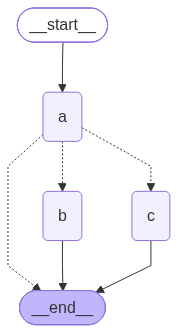


✅ HITL 그래프 구성 완료
💡 node_a에서 Command를 사용하여 상태 업데이트와 라우팅을 동시에 처리


In [ ]:
# HITL 그래프 구성
hitl_builder = StateGraph(HITLState)

# 노드 추가
hitl_builder.add_node("a", hitl_node_a)
hitl_builder.add_node("b", hitl_node_b)
hitl_builder.add_node("c", hitl_node_c)

# 엣지 추가 (node_a는 Command로 직접 라우팅하므로 별도 엣지 불필요)
hitl_builder.add_edge(START, "a")
hitl_builder.add_edge("b", END)
hitl_builder.add_edge("c", END)

# 컴파일 (checkpointer 필수!)
hitl_graph = hitl_builder.compile(checkpointer=hitl_memory)

# 시각화
display(Image(hitl_graph.get_graph().draw_mermaid_png()))
print("\n✅ HITL 그래프 구성 완료")
print("💡 node_a에서 Command를 사용하여 상태 업데이트와 라우팅을 동시에 처리")

#### HITL 실행 테스트

직접 입력하면서 테스트해봅니다.
- `b` 입력 → Node B로 이동
- `c` 입력 → Node C로 이동  
- `q` 입력 → 종료
- **그 외 입력** → interrupt 발생 → 관리자 응답 대기

In [ ]:
# 대화형 HITL 테스트
hitl_config_interactive = {"configurable": {"thread_id": "hitl_interactive"}}

print("🎮 HITL 대화형 테스트")
print("=" * 50)
print("사용법: b(→B노드), c(→C노드), q(종료), 그 외(→interrupt)")
print("=" * 50)

while True:
    user_input = input("\n입력 (b/c/q/기타): ")

    # 그래프 실행
    result = hitl_graph.invoke({"messages": [user_input]}, hitl_config_interactive)

    # interrupt 발생 확인 및 처리
    if "__interrupt__" in result:
        print(f"\n🛑 Interrupt 발생!")
        interrupt_msg = result["__interrupt__"][-1].value
        print(f"메시지: {interrupt_msg}")

        # 관리자 응답 받기
        admin_input = input("\n👤 관리자 응답 (continue=계속/quit=종료): ")

        # 그래프 재개

    print(f"📊 결과: {result['messages']}")

    # 종료 조건 확인
    if user_input == "q" or (result["messages"] and "→__end__" in str(result["messages"][-1])):
        print("\n👋 테스트 종료!")
        break

🎮 HITL 대화형 테스트
사용법: b(→B노드), c(→C노드), q(종료), 그 외(→interrupt)

입력 (b/c/q/기타): b
  [Node A] 현재 상태: ['b']
  [Node B] 현재 상태: ['b', 'A→b']
📊 결과: ['b', 'A→b', 'B 처리완료']

입력 (b/c/q/기타): hi
  [Node A] 현재 상태: ['b', 'A→b', 'B 처리완료', 'hi']

🛑 Interrupt 발생!
메시지: ⚠️ 예상치 못한 입력: 'hi' - 어떻게 처리할까요?

👤 관리자 응답 (continue=계속/quit=종료): continuje
  [Node A] 현재 상태: ['b', 'A→b', 'B 처리완료', 'hi']
  [Admin 응답] continuje

✅ 그래프 재개됨!
📊 결과: ['b', 'A→b', 'B 처리완료', 'hi', 'A→__end__']

👋 테스트 종료!


```markdown
### 💡 실무 관점의 HITL (Human-In-The-Loop) & Command 제어 설계 노트

대화형 에이전트 시스템에서 사람이 직접 승인하거나 검토하는 기능을 구현할 때 반드시 이해해야 하는 핵심 설계 구조 요약입니다.

#### 🗺️ 1. 내부 그래프 정의(공장) vs 외부 실행 루프(조종실)
* **내부 그래프 정의 영역**: 노드 함수(`hitl_node_a` 등)와 엣지 규칙이 정의되는 **자동화 공장 설계도**입니다.
* **외부 실행 루프 영역 (`while True`)**: 바깥에서 `input()`으로 사용자의 입력을 받고, `invoke()`로 그래프를 작동시키며 전체 대화 세션을 관리하는 **조종실 화면**입니다.
* **역할 분담**: 바깥의 실행 루프는 단순히 데이터를 실어 나르는 우체부 역할만 담당하고, 실제 "상태가 이렇다면 `continue`할지 `quit`할지"에 대한 비즈니스 판단은 내부의 노드(`hitl_node_a` 등)가 상태 값을 읽어 스스로 내립니다.

#### 💾 2. 메모리와 세이브 파일 관리 (`MemorySaver` & `thread_id`)
* **`compile(checkpointer=hitl_memory)`**: 노드를 하나씩 올리는 단계(`add_node`)에서는 메모리가 관여하지 않으며, 그래프 빌더를 통해 최종적으로 에이전트 패키지를 조립하는 `.compile()` 단계에서 비로소 **데이터 금고(세이브 시스템)**가 장착됩니다.
* **`thread_id`**: 금고 안에 보관된 수많은 과거 실행 기록 중, 어떤 사용자의 것인지 구분하는 **'세이브 파일 이름표(라벨)'**입니다. 동일한 `thread_id`로 요청을 넣어야만 이전 대화 기록과 중단점 위치가 안전하게 이어서 복원됩니다.

#### 🛑 3. 비동기 서버 구조와 `interrupt` (서버가 마비되지 않는 비결)
* **블로킹(Blocking)의 위험성**: 만약 다중 사용자가 쓰는 서버에서 사용자가 답장할 때까지 서버가 그 자리에서 `time.sleep()`처럼 마냥 대기한다면, 서버 일꾼(스레드)이 금방 묶여 전체 서비스가 다운(Thread Starvation)됩니다.
* **LangGraph의 해결책**:
  1. 노드 안에서 사람의 피드백이 필요할 때 `interrupt()`를 선언하면, 시스템은 그 즉시 **현재까지의 상태를 금고에 저장하고 완벽히 실행을 종료(완전 퇴근)**합니다.
  2. 서버는 리소스를 아끼며 즉시 다른 사용자들의 요청을 자유롭게 처리하러 가고, 사용자는 화면(UI)에서만 멈춘 채 답변을 입력합니다.
  3. 사용자가 입력을 마치면 외부 루프에서 `Command(resume=값)`를 통해 서버를 다시 깨워, 끊겼던 `interrupt` 지점부터 막힘없이 이어나갑니다.

#### 🎛️ 4. 마법의 제어 패키지 `Command` 의 3가지 핵심 기능
`Command`는 노드가 실행 도중 엔진에게 *"내 지시대로 다음 동작을 처리해 줘!"*라고 강제로 내리는 공식 제어 리모컨입니다.
* **`Command(goto="node_name")` (동적 라우팅)**: 미리 고정된 선형 엣지 경로를 무시하고, 비즈니스 규칙에 맞춰 실시간으로 다음 진행 노드를 동적으로 설정합니다.
* **`Command(update={...})` (상태 갱신)**: 다음 목적지로 이동하기 직전에 데이터 금고에 새로운 데이터나 누적 기록을 꾹꾹 눌러 담아 강제로 업데이트합니다.
* **`Command(resume="값")` (재개)**: `interrupt` 때문에 얼어붙어 있는 노드에게 외부에서 받은 결정이나 피드백 값(`admin_input`)을 전달해주며 멈췄던 흐름을 우아하게 깨우는 도구입니다.
```

#### interrupt()와 Command 이해하기

| 개념 | 코드 | 설명 |
|------|------|------|
| **interrupt()** | `interrupt("메시지")` | 그래프 실행을 일시 정지하고 사람 입력 대기 |
| **Command (update)** | `Command(update={...})` | 상태 업데이트 |
| **Command (goto)** | `Command(goto="node")` | 다음 노드 지정 (동적 라우팅) |
| **Command (resume)** | `Command(resume="값")` | 일시 정지된 그래프 재개 |

```python
# interrupt 발생
admin_response = interrupt("예외 상황 발생!")
# → 그래프 일시 정지, admin_response는 재개 시 받은 값

# 그래프 재개
result = graph.invoke(Command(resume="continue"), config)
# → interrupt() 함수가 "continue" 값을 반환하며 재개
```

### LangGraph Essentials 정리

| 개념 | 코드 | 설명 |
|------|------|------|
| **State** | `class MyState(TypedDict)` | 그래프 전체 공유 데이터 |
| **Reducer** | `Annotated[List, operator.add]` | 값 누적 (덮어쓰기 방지) |
| **Node** | `def my_node(state) -> state` | 상태를 받아 처리하는 함수 |
| **Edge** | `add_edge("a", "b")` | 노드 간 연결 (순서 정의) |
| **Parallel** | 한 노드에서 여러 Edge | 동시 실행 후 병합 |
| **Conditional** | `add_conditional_edges()` | 상태 기반 동적 라우팅 |
| **Memory** | `compile(checkpointer=memory)` | 호출 간 상태 유지 |
| **HITL** | `interrupt()` + `Command(resume=)` | 사람 입력 대기 후 재개 |

**핵심 패턴**: `State 정의` → `Node 작성` → `Edge 연결` → `compile()` → `invoke()`